In [1]:
# Встановлення залежностей (розкоментуйте за необхідності)
# !pip install tensorflow mlflow optuna scikit-learn pandas numpy matplotlib seaborn

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

import mlflow
import mlflow.tensorflow

import optuna
from optuna.samplers import TPESampler
optuna.logging.set_verbosity(optuna.logging.WARNING)

np.random.seed(42)
tf.random.set_seed(42)

print(f'TensorFlow : {tf.__version__}')
print(f'MLflow     : {mlflow.__version__}')
print(f'Optuna     : {optuna.__version__}')

TensorFlow : 2.21.0
MLflow     : 3.12.0
Optuna     : 4.8.0


In [3]:
housing = fetch_california_housing()
X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = pd.Series(housing.target, name='MedHouseVal')

print('=== Форма датасету ===')
print(f'X shape : {X.shape}')
print(f'y shape : {y.shape}')
print()
print('=== Перші 5 рядків ===')
display(X.head())
print()
print('=== Описова статистика ===')
display(X.describe().round(3))
print()
print('=== Пропущені значення ===')
print(X.isnull().sum())

=== Форма датасету ===
X shape : (20640, 8)
y shape : (20640,)

=== Перші 5 рядків ===


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25



=== Описова статистика ===


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000
mean,3.871,28.639,5.429,1.097,1425.477,3.071,35.632,-119.570
std,1.900,12.586,2.474,0.474,1132.462,10.386,2.136,2.004
min,0.500,1.000,0.846,0.333,3.000,0.692,32.540,-124.350
25%,2.563,18.000,4.441,1.006,787.000,2.430,33.930,-121.800
50%,3.535,29.000,5.229,1.049,1166.000,2.818,34.260,-118.490
75%,4.743,37.000,6.052,1.100,1725.000,3.282,37.710,-118.010
max,15.000,52.000,141.909,34.067,35682.000,1243.333,41.950,-114.310



=== Пропущені значення ===
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64


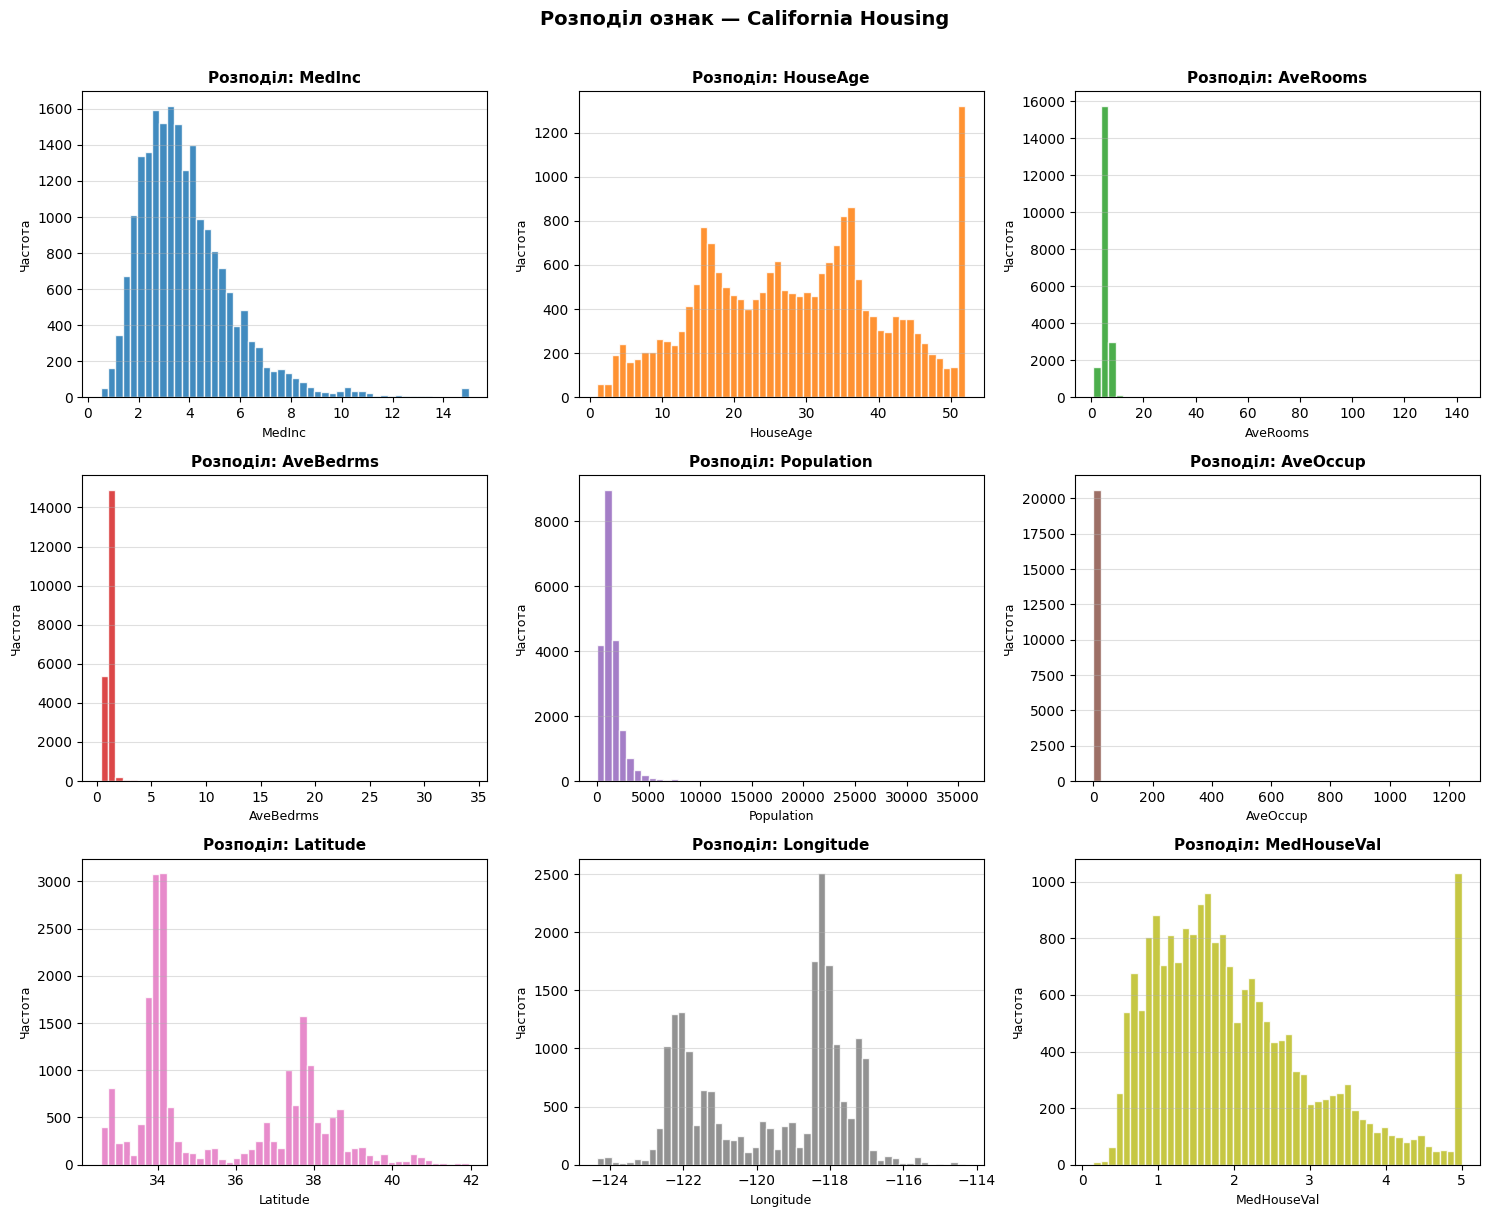

Гістограми збережено: lab1_feature_distributions.png


In [4]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
all_cols = list(X.columns) + ['MedHouseVal']
all_data = pd.concat([X, y], axis=1)

colors = plt.cm.tab10.colors
for i, col in enumerate(all_cols):
    axes[i].hist(all_data[col], bins=50, color=colors[i % 10], edgecolor='white', alpha=0.85)
    axes[i].set_title(f'Розподіл: {col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=9)
    axes[i].set_ylabel('Частота', fontsize=9)
    axes[i].grid(axis='y', alpha=0.4)

plt.suptitle('Розподіл ознак — California Housing', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('lab1_feature_distributions.png', dpi=120, bbox_inches='tight')
plt.show()
print('Гістограми збережено: lab1_feature_distributions.png')

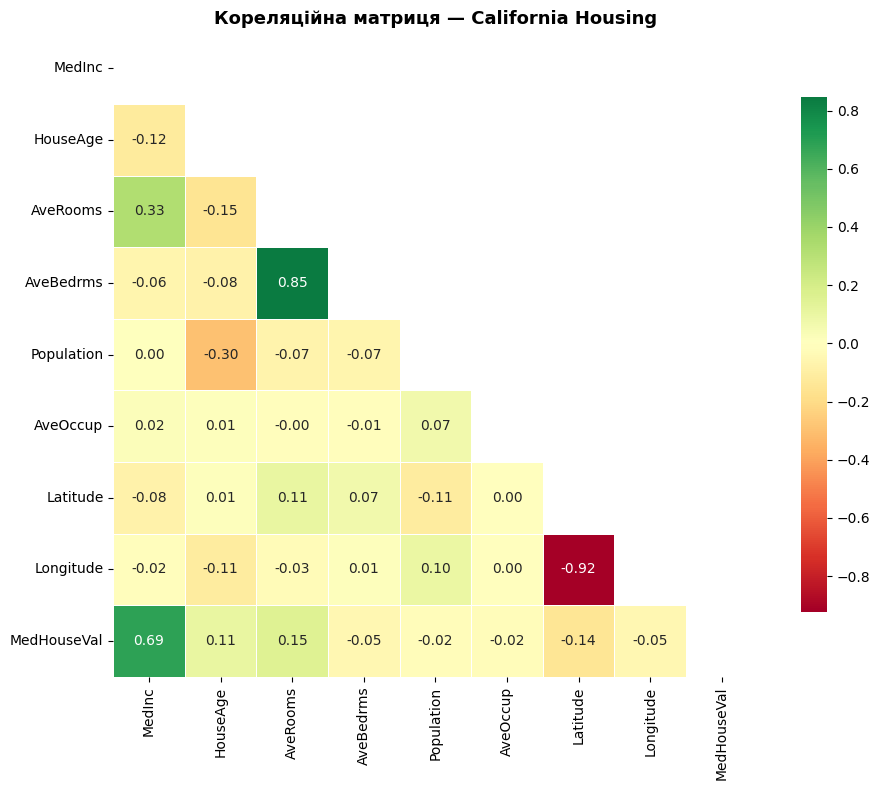

Кореляції з цільовою змінною MedHouseVal:
MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160


In [5]:
df_full = pd.concat([X, y], axis=1)
corr = df_full.corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Кореляційна матриця — California Housing', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('lab1_correlation_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

print('Кореляції з цільовою змінною MedHouseVal:')
print(corr['MedHouseVal'].sort_values(ascending=False).to_string())

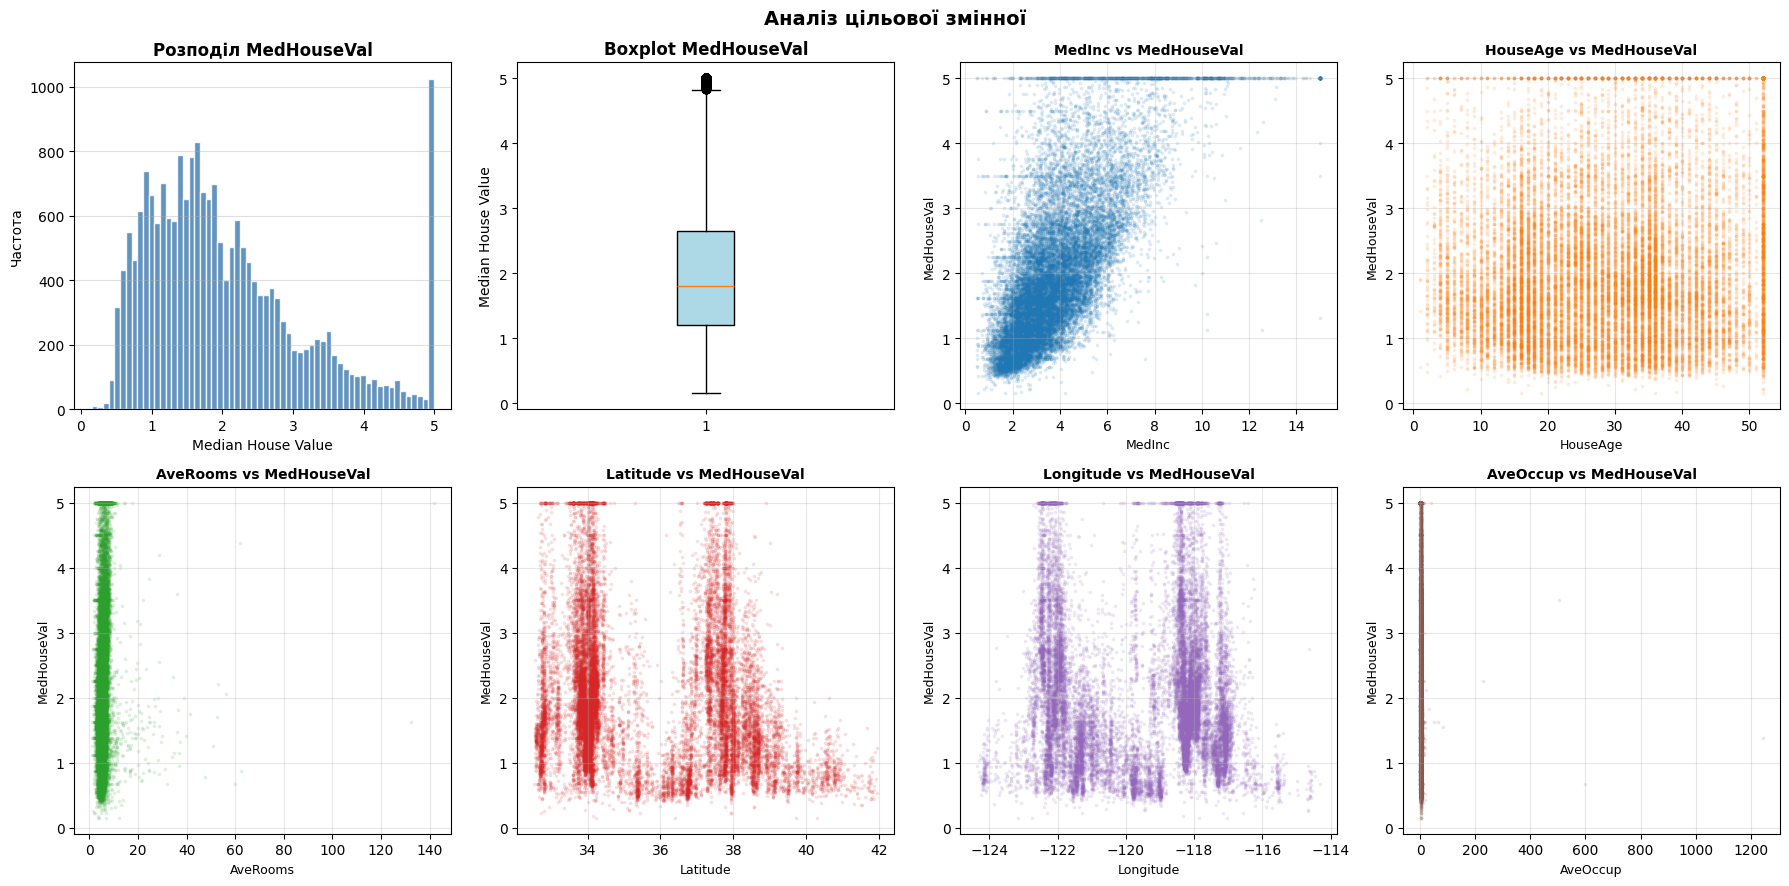

Цільова змінна — описова статистика:
count    20640.0000
mean         2.0686
std          1.1540
min          0.1500
25%          1.1960
50%          1.7970
75%          2.6472
max          5.0000
Name: MedHouseVal, dtype: float64


In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

# Гістограма та boxplot цілі
axes[0].hist(y, bins=60, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].set_title('Розподіл MedHouseVal', fontweight='bold')
axes[0].set_xlabel('Median House Value')
axes[0].set_ylabel('Частота')
axes[0].grid(axis='y', alpha=0.4)

axes[1].boxplot(y, patch_artist=True, boxprops=dict(facecolor='lightblue'))
axes[1].set_title('Boxplot MedHouseVal', fontweight='bold')
axes[1].set_ylabel('Median House Value')

# Scatter-plots для ключових ознак
key_features = ['MedInc', 'HouseAge', 'AveRooms', 'Latitude', 'Longitude', 'AveOccup']
for i, feat in enumerate(key_features):
    axes[i + 2].scatter(X[feat], y, alpha=0.1, s=3, color=colors[i])
    axes[i + 2].set_xlabel(feat, fontsize=9)
    axes[i + 2].set_ylabel('MedHouseVal', fontsize=9)
    axes[i + 2].set_title(f'{feat} vs MedHouseVal', fontweight='bold', fontsize=10)
    axes[i + 2].grid(alpha=0.3)

plt.suptitle('Аналіз цільової змінної', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('lab1_target_analysis.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Цільова змінна — описова статистика:\n{y.describe().round(4)}')

In [7]:
# --- Feature Engineering: log-трансформація правоскошених ознак ---
# AveRooms, AveBedrms, Population, AveOccup мають сильний правий скос
log_cols = ['AveRooms', 'AveBedrms', 'Population', 'AveOccup']
X_fe = X.copy()
for col in log_cols:
    X_fe[col] = np.log1p(X_fe[col])

# --- Кліпінг викидів (1-й та 99-й перцентиль) ---
for col in X_fe.columns:
    lo, hi = X_fe[col].quantile(0.01), X_fe[col].quantile(0.99)
    X_fe[col] = X_fe[col].clip(lo, hi)

X_arr = X_fe.values.astype(np.float32)
y_arr = y.values.astype(np.float32).reshape(-1, 1)

# --- Train / Validation / Test split (70 / 15 / 15) ---
# Спочатку розбиваємо, потім масштабуємо (щоб уникнути витоку даних)
X_temp, X_test_raw, y_temp, y_test_raw = train_test_split(
    X_arr, y_arr, test_size=0.15, random_state=42)
X_train_raw, X_val_raw, y_train_raw, y_val_raw = train_test_split(
    X_temp, y_temp, test_size=0.1765, random_state=42)  # ~0.15 від загального

# --- Стандартизація ---
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_sc = scaler_X.fit_transform(X_train_raw)
X_val_sc   = scaler_X.transform(X_val_raw)
X_test_sc  = scaler_X.transform(X_test_raw)

y_train = scaler_y.fit_transform(y_train_raw).flatten()
y_val   = scaler_y.transform(y_val_raw).flatten()
y_test  = scaler_y.transform(y_test_raw).flatten()

print(f'Train size       : {X_train_sc.shape[0]:>6} ({X_train_sc.shape[0]/X_arr.shape[0]*100:.1f}%)')
print(f'Validation size  : {X_val_sc.shape[0]:>6} ({X_val_sc.shape[0]/X_arr.shape[0]*100:.1f}%)')
print(f'Test size        : {X_test_sc.shape[0]:>6} ({X_test_sc.shape[0]/X_arr.shape[0]*100:.1f}%)')
print(f'Original features: {X_train_sc.shape[1]}')
print(f'Log-трансформовано: {log_cols}')

Train size       :  14447 (70.0%)
Validation size  :   3097 (15.0%)
Test size        :   3096 (15.0%)
Original features: 8
Log-трансформовано: ['AveRooms', 'AveBedrms', 'Population', 'AveOccup']


Ознак після PolynomialFeatures(degree=2): 8 → 44


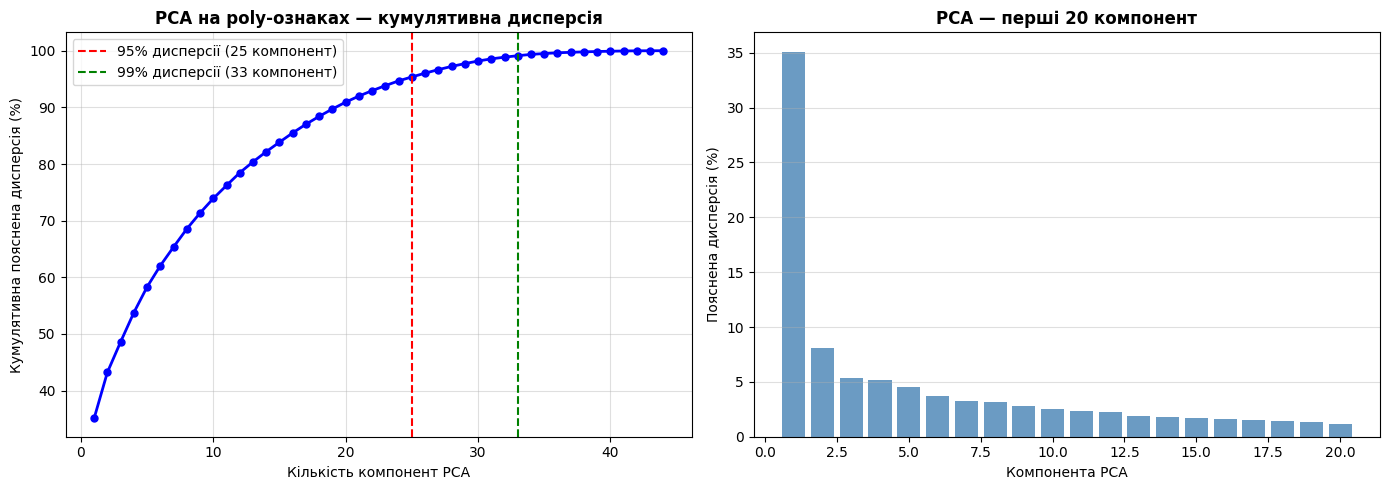

Poly-ознак всього        : 44
Компонент для 95% дисп.  : 25
Компонент для 99% дисп.  : 33

PCA застосовано: 44 → 25 компонент
Фінальна розмірність вхідних даних: 25


In [8]:
# --- Крок 1: Polynomial Features (degree=2) ---
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_sc)
X_val_poly   = poly.transform(X_val_sc)
X_test_poly  = poly.transform(X_test_sc)
print(f'Ознак після PolynomialFeatures(degree=2): {X_train_sc.shape[1]} → {X_train_poly.shape[1]}')

# --- Крок 2: PCA — аналіз дисперсії ---
pca_full = PCA().fit(X_train_poly)
cum_var  = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.argmax(cum_var >= 0.95)) + 1
n99 = int(np.argmax(cum_var >= 0.99)) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, len(cum_var) + 1), cum_var * 100, 'bo-', linewidth=2, markersize=5)
axes[0].axvline(x=n95, color='r', linestyle='--', label=f'95% дисперсії ({n95} компонент)')
axes[0].axvline(x=n99, color='g', linestyle='--', label=f'99% дисперсії ({n99} компонент)')
axes[0].set_xlabel('Кількість компонент PCA')
axes[0].set_ylabel('Кумулятивна пояснена дисперсія (%)')
axes[0].set_title('PCA на poly-ознаках — кумулятивна дисперсія', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.4)

top_n = min(20, X_train_poly.shape[1])
axes[1].bar(range(1, top_n + 1),
            pca_full.explained_variance_ratio_[:top_n] * 100, color='steelblue', alpha=0.8)
axes[1].set_xlabel('Компонента PCA')
axes[1].set_ylabel('Пояснена дисперсія (%)')
axes[1].set_title(f'PCA — перші {top_n} компонент', fontweight='bold')
axes[1].grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig('lab1_pca_analysis.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Poly-ознак всього        : {X_train_poly.shape[1]}')
print(f'Компонент для 95% дисп.  : {n95}')
print(f'Компонент для 99% дисп.  : {n99}')

# --- Крок 3: Застосування PCA (95% дисперсії) ---
pca = PCA(n_components=n95, random_state=42)
X_train = pca.fit_transform(X_train_poly).astype(np.float32)
X_val   = pca.transform(X_val_poly).astype(np.float32)
X_test  = pca.transform(X_test_poly).astype(np.float32)

print(f'\nPCA застосовано: {X_train_poly.shape[1]} → {X_train.shape[1]} компонент')
print(f'Фінальна розмірність вхідних даних: {X_train.shape[1]}')

In [9]:
mlflow.set_tracking_uri('./mlruns_lab1')
mlflow.set_experiment('California_Housing_TensorFlow')

print('MLflow tracking URI :', mlflow.get_tracking_uri())
print('Experiment          : California_Housing_TensorFlow')
print('Runs зберігаються в : ./mlruns_lab1')

# Словник для збереження результатів усіх моделей
results = {}

MLflow tracking URI : ./mlruns_lab1
Experiment          : California_Housing_TensorFlow
Runs зберігаються в : ./mlruns_lab1


In [10]:
def build_basic_model(input_dim, activation='relu', lr=0.001):
    """Базова FF мережа: 2 приховані шари."""
    inputs = keras.Input(shape=(input_dim,), name='input')
    x = layers.Dense(128, name='hidden1')(inputs)
    if activation == 'leaky_relu':
        x = layers.LeakyReLU(negative_slope=0.2, name='act1')(x)
    elif activation == 'gelu':
        x = layers.Activation('gelu', name='act1')(x)
    else:
        x = layers.Activation('relu', name='act1')(x)

    x = layers.Dense(64, name='hidden2')(x)
    if activation == 'leaky_relu':
        x = layers.LeakyReLU(negative_slope=0.2, name='act2')(x)
    elif activation == 'gelu':
        x = layers.Activation('gelu', name='act2')(x)
    else:
        x = layers.Activation('relu', name='act2')(x)

    outputs = layers.Dense(1, name='output')(x)

    model = keras.Model(inputs, outputs, name=f'basic_{activation}')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='mse',
        metrics=['mae']
    )
    return model

print('Базова модель (ReLU):')
build_basic_model(8, 'relu').summary()

Базова модель (ReLU):


Model: "basic_relu"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden1 (Dense)                 │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act1 (Activation)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act2 (Activation)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,473 (37.00 KB)

 Trainable params: 9,473 (37.00 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
def build_advanced_model(input_dim, activation='relu', lr=0.001,
                         dropout=0.3, l2_reg=1e-4):
    """Розширена FF мережа з Dropout, BatchNormalization та L2-регуляризацією."""
    inputs = keras.Input(shape=(input_dim,), name='input')

    x = layers.Dense(256, kernel_regularizer=regularizers.l2(l2_reg), name='h1')(inputs)
    x = layers.BatchNormalization(name='bn1')(x)
    if activation == 'leaky_relu':
        x = layers.LeakyReLU(negative_slope=0.2, name='act1')(x)
    elif activation == 'gelu':
        x = layers.Activation('gelu', name='act1')(x)
    else:
        x = layers.Activation('relu', name='act1')(x)
    x = layers.Dropout(dropout, name='drop1')(x)

    x = layers.Dense(128, kernel_regularizer=regularizers.l2(l2_reg), name='h2')(x)
    x = layers.BatchNormalization(name='bn2')(x)
    if activation == 'leaky_relu':
        x = layers.LeakyReLU(negative_slope=0.2, name='act2')(x)
    elif activation == 'gelu':
        x = layers.Activation('gelu', name='act2')(x)
    else:
        x = layers.Activation('relu', name='act2')(x)
    x = layers.Dropout(dropout, name='drop2')(x)

    x = layers.Dense(64, kernel_regularizer=regularizers.l2(l2_reg), name='h3')(x)
    x = layers.BatchNormalization(name='bn3')(x)
    if activation == 'leaky_relu':
        x = layers.LeakyReLU(negative_slope=0.2, name='act3')(x)
    elif activation == 'gelu':
        x = layers.Activation('gelu', name='act3')(x)
    else:
        x = layers.Activation('relu', name='act3')(x)
    x = layers.Dropout(dropout / 2, name='drop3')(x)

    outputs = layers.Dense(1, name='output')(x)

    model = keras.Model(inputs, outputs, name=f'advanced_{activation}')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='mse',
        metrics=['mae']
    )
    return model

print('Розширена модель (ReLU):')
build_advanced_model(8, 'relu').summary()

Розширена модель (ReLU):


Model: "advanced_relu"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ h1 (Dense)                      │ (None, 256)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act1 (Activation)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ h2 (Dense)                      │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act2 (Activation)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ h3 (Dense)                      │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act3 (Activation)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop3 (Dropout)                 │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 45,313 (177.00 KB)

 Trainable params: 44,417 (173.50 KB)

 Non-trainable params: 896 (3.50 KB)

In [12]:
EPOCHS = 30
BATCH_SIZE = 128
INPUT_DIM = X_train.shape[1]

def evaluate_model(model, X_t, y_t_scaled):
    """Повертає метрики в оригінальному масштабі."""
    y_pred_scaled = model.predict(X_t, verbose=0).flatten()
    y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
    y_true = scaler_y.inverse_transform(y_t_scaled.reshape(-1, 1)).flatten()
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    # Accuracy@10%: відсоток передбачень, які відхиляються не більше ніж на 10% від реального значення
    acc_10 = float(np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, 1e-8, y_true)) <= 0.1) * 100)
    return {'mse': mse, 'rmse': rmse, 'mae': mae, 'r2': r2, 'acc_10': acc_10}

def train_and_log(name, model, arch_type, activation, lr, run_tag=None):
    """Навчає модель і логує в MLflow."""
    run_name = run_tag or name
    with mlflow.start_run(run_name=run_name):
        mlflow.log_param('architecture', arch_type)
        mlflow.log_param('activation', activation)
        mlflow.log_param('learning_rate', lr)
        mlflow.log_param('epochs', EPOCHS)
        mlflow.log_param('batch_size', BATCH_SIZE)
        mlflow.log_param('optimizer', 'Adam')

        cb_es = keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5, restore_best_weights=True)
        cb_lr = keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=3, verbose=0)

        history = model.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=[cb_es, cb_lr],
            verbose=0
        )

        metrics = evaluate_model(model, X_test, y_test)
        for k, v in metrics.items():
            mlflow.log_metric(f'test_{k}', v)

        mlflow.tensorflow.log_model(model, artifact_path='model')

        print(f'[{name:40s}] RMSE={metrics["rmse"]:.4f}  MAE={metrics["mae"]:.4f}  R²={metrics["r2"]:.4f}  Accuracy@10%={metrics["acc_10"]:.2f}%')
    return history, metrics

In [13]:
print('=' * 75)
print('БАЗОВІ МОДЕЛІ')
print('=' * 75)

activations = ['relu', 'leaky_relu', 'gelu']
histories_basic = {}

for act in activations:
    model = build_basic_model(INPUT_DIM, activation=act, lr=0.001)
    hist, met = train_and_log(
        name=f'basic_{act}',
        model=model,
        arch_type='basic',
        activation=act,
        lr=0.001
    )
    histories_basic[act] = hist
    results[f'basic_{act}'] = met

БАЗОВІ МОДЕЛІ


2026/05/10 22:44:33 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/10 22:44:33 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


[basic_relu                              ] RMSE=0.5929  MAE=0.4116  R²=0.7318  Accuracy@10%=33.24%


2026/05/10 22:44:43 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/10 22:44:43 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


[basic_leaky_relu                        ] RMSE=0.6048  MAE=0.4216  R²=0.7209  Accuracy@10%=31.78%


2026/05/10 22:44:52 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/10 22:44:52 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


[basic_gelu                              ] RMSE=0.5910  MAE=0.4122  R²=0.7335  Accuracy@10%=33.66%


In [14]:
print('=' * 75)
print('РОЗШИРЕНІ МОДЕЛІ (Dropout + BatchNorm + L2)')
print('=' * 75)

histories_advanced = {}

for act in ['relu', 'gelu']:  # дві активації для розширеної
    model = build_advanced_model(INPUT_DIM, activation=act, lr=0.001,
                                  dropout=0.3, l2_reg=1e-4)
    hist, met = train_and_log(
        name=f'advanced_{act}',
        model=model,
        arch_type='advanced',
        activation=act,
        lr=0.001
    )
    histories_advanced[act] = hist
    results[f'advanced_{act}'] = met

РОЗШИРЕНІ МОДЕЛІ (Dropout + BatchNorm + L2)


2026/05/10 22:45:05 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/10 22:45:05 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


[advanced_relu                           ] RMSE=0.5820  MAE=0.4053  R²=0.7415  Accuracy@10%=32.62%


2026/05/10 22:45:21 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/10 22:45:21 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


[advanced_gelu                           ] RMSE=0.5894  MAE=0.4127  R²=0.7350  Accuracy@10%=32.46%


In [15]:
def optuna_objective(trial):
    """Objective-функція для Optuna."""
    lr         = trial.suggest_float('lr', 5e-5, 5e-3, log=True)
    n_units_1  = trial.suggest_categorical('n_units_1', [128, 256, 512])
    n_units_2  = trial.suggest_categorical('n_units_2', [64, 128, 256])
    n_units_3  = trial.suggest_categorical('n_units_3', [32, 64, 128])
    dropout    = trial.suggest_float('dropout', 0.05, 0.4)
    l2_reg     = trial.suggest_float('l2_reg', 1e-6, 1e-3, log=True)
    activation = trial.suggest_categorical('activation', ['relu', 'leaky_relu', 'gelu'])
    batch_size = trial.suggest_categorical('batch_size', [64, 128, 256])

    inputs = keras.Input(shape=(INPUT_DIM,))

    def apply_act(x, act, name):
        if act == 'leaky_relu':
            return layers.LeakyReLU(negative_slope=0.2, name=name)(x)
        elif act == 'gelu':
            return layers.Activation('gelu', name=name)(x)
        return layers.Activation('relu', name=name)(x)

    x = layers.Dense(n_units_1, kernel_regularizer=regularizers.l2(l2_reg))(inputs)
    x = layers.BatchNormalization()(x)
    x = apply_act(x, activation, 'a1')
    x = layers.Dropout(dropout)(x)

    x = layers.Dense(n_units_2, kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = apply_act(x, activation, 'a2')
    x = layers.Dropout(dropout / 2)(x)

    x = layers.Dense(n_units_3, kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = apply_act(x, activation, 'a3')

    outputs = layers.Dense(1)(x)

    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='mse', metrics=['mae'])

    cb_es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=6,
                                           restore_best_weights=True)
    cb_lr = keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                               patience=3, verbose=0)
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=30, batch_size=batch_size,
        callbacks=[cb_es, cb_lr], verbose=0
    )

    val_loss = min(history.history['val_loss'])
    return val_loss

print('Запуск Optuna (40 trials)...')
study = optuna.create_study(direction='minimize', sampler=TPESampler(seed=42))
study.optimize(optuna_objective, n_trials=40, show_progress_bar=True)

print()
print(f'Найкращий val_loss : {study.best_value:.6f}')
print('Найкращі параметри :')
for k, v in study.best_params.items():
    print(f'  {k:15s}: {v}')

Запуск Optuna (40 trials)...


  0%|          | 0/40 [00:00<?, ?it/s]


Найкращий val_loss : 0.251437
Найкращі параметри :
  lr             : 0.0033034421349003936
  n_units_1      : 512
  n_units_2      : 128
  n_units_3      : 64
  dropout        : 0.18732074666667436
  l2_reg         : 2.5910054486241363e-06
  activation     : relu
  batch_size     : 256


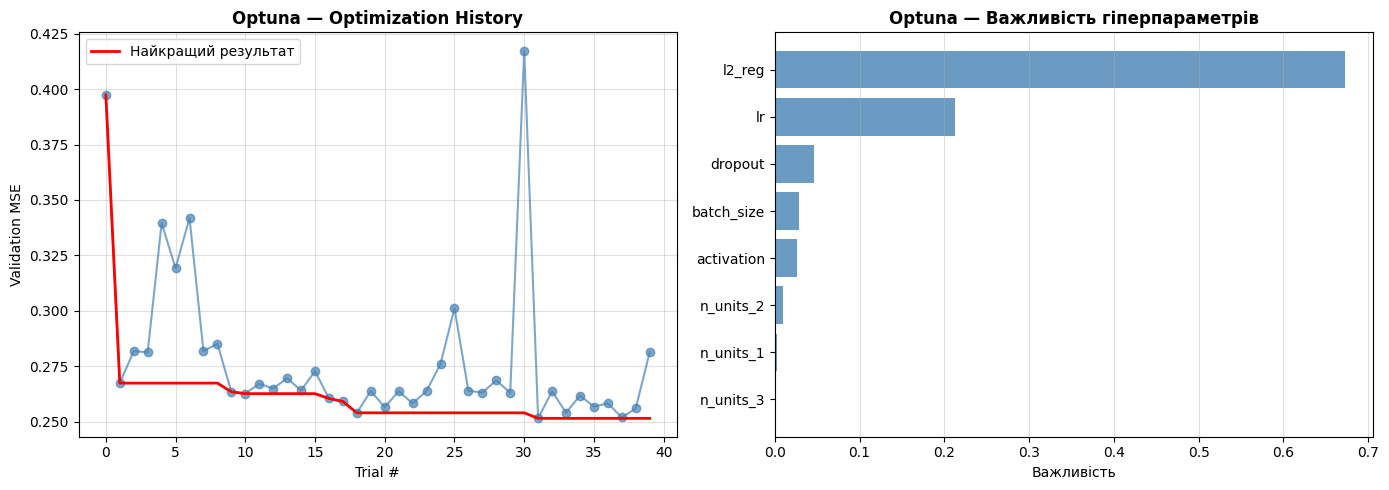

In [16]:
# Візуалізація результатів Optuna
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Optimization history
trial_vals = [t.value for t in study.trials if t.value is not None]
axes[0].plot(trial_vals, 'o-', color='steelblue', alpha=0.7)
axes[0].plot(np.minimum.accumulate(trial_vals), 'r-', linewidth=2, label='Найкращий результат')
axes[0].set_xlabel('Trial #')
axes[0].set_ylabel('Validation MSE')
axes[0].set_title('Optuna — Optimization History', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.4)

# Parameter importance (якщо доступно)
try:
    importances = optuna.importance.get_param_importances(study)
    params_sorted = sorted(importances.items(), key=lambda x: x[1])
    axes[1].barh([p[0] for p in params_sorted], [p[1] for p in params_sorted],
                  color='steelblue', alpha=0.8)
    axes[1].set_xlabel('Важливість')
    axes[1].set_title('Optuna — Важливість гіперпараметрів', fontweight='bold')
    axes[1].grid(axis='x', alpha=0.4)
except Exception as e:
    axes[1].text(0.5, 0.5, f'Важливість недоступна:\n{e}', ha='center', va='center',
                  transform=axes[1].transAxes)

plt.tight_layout()
plt.savefig('lab1_optuna_results.png', dpi=120, bbox_inches='tight')
plt.show()

In [17]:
best = study.best_params

print('Навчання найкращої моделі з параметрами Optuna...')
with mlflow.start_run(run_name='optuna_best_model'):
    for k, v in best.items():
        mlflow.log_param(k, v)
    mlflow.log_param('source', 'optuna')
    mlflow.log_param('epochs', EPOCHS)

    inputs = keras.Input(shape=(INPUT_DIM,))

    def apply_act_best(x, act, name):
        if act == 'leaky_relu':
            return layers.LeakyReLU(negative_slope=0.2, name=name)(x)
        elif act == 'gelu':
            return layers.Activation('gelu', name=name)(x)
        return layers.Activation('relu', name=name)(x)

    x = layers.Dense(best['n_units_1'],
                     kernel_regularizer=regularizers.l2(best['l2_reg']))(inputs)
    x = layers.BatchNormalization()(x)
    x = apply_act_best(x, best['activation'], 'a1')
    x = layers.Dropout(best['dropout'])(x)

    x = layers.Dense(best['n_units_2'],
                     kernel_regularizer=regularizers.l2(best['l2_reg']))(x)
    x = layers.BatchNormalization()(x)
    x = apply_act_best(x, best['activation'], 'a2')
    x = layers.Dropout(best['dropout'] / 2)(x)

    x = layers.Dense(best['n_units_3'],
                     kernel_regularizer=regularizers.l2(best['l2_reg']))(x)
    x = layers.BatchNormalization()(x)
    x = apply_act_best(x, best['activation'], 'a3')

    out = layers.Dense(1)(x)
    best_model = keras.Model(inputs, out, name='optuna_best')
    best_model.compile(
        optimizer=keras.optimizers.Adam(best['lr']),
        loss='mse', metrics=['mae']
    )

    cb_es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                           restore_best_weights=True)
    cb_lr = keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)

    history_best = best_model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS, batch_size=best['batch_size'],
        callbacks=[cb_es, cb_lr], verbose=1
    )

    met_best = evaluate_model(best_model, X_test, y_test)
    for k, v in met_best.items():
        mlflow.log_metric(f'test_{k}', v)
    mlflow.tensorflow.log_model(best_model, artifact_path='model')
    results['optuna_best'] = met_best

print()
print(f'Optuna Best: RMSE={met_best["rmse"]:.4f}  MAE={met_best["mae"]:.4f}  R²={met_best["r2"]:.4f}  Accuracy@10%={met_best["acc_10"]:.2f}%')

Навчання найкращої моделі з параметрами Optuna...
Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.5676 - mae: 0.5359 - val_loss: 0.4410 - val_mae: 0.4806 - learning_rate: 0.0033
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3434 - mae: 0.4270 - val_loss: 0.3481 - val_mae: 0.4276 - learning_rate: 0.0033
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3055 - mae: 0.4005 - val_loss: 0.3042 - val_mae: 0.4060 - learning_rate: 0.0033
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2895 - mae: 0.3892 - val_loss: 0.2933 - val_mae: 0.3900 - learning_rate: 0.0033
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2782 - mae: 0.3797 - val_loss: 0.2874 - val_mae: 0.3771 - learning_rate: 0.0033
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2719 - mae: 0.3756 - val_loss: 0.2903 - val_mae: 0.3701 - learning_rate: 0.0033
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2635 - mae: 0.3675 - val_loss: 0.2744 - val_mae: 0

2026/05/10 22:50:45 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/10 22:50:45 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.



Optuna Best: RMSE=0.5689  MAE=0.3920  R²=0.7530  Accuracy@10%=34.95%


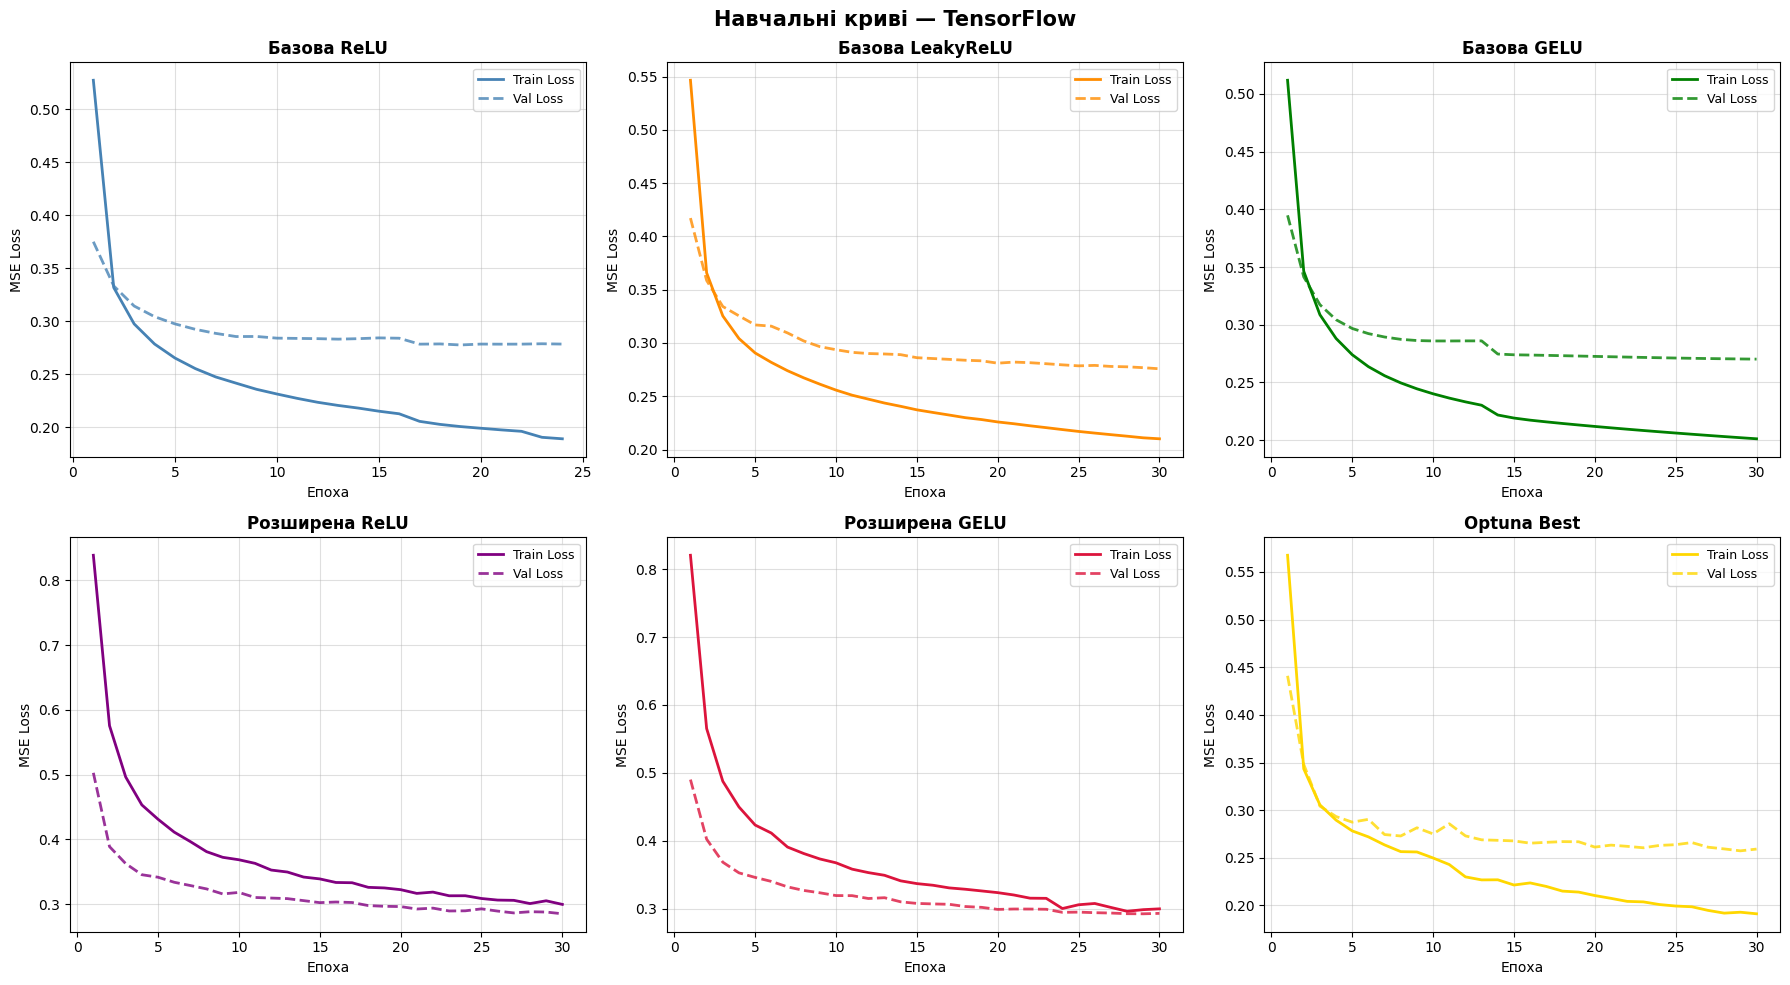

Навчальні криві збережено: lab1_learning_curves.png


In [18]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

plot_configs = [
    ('Базова ReLU',       histories_basic.get('relu'),      'steelblue'),
    ('Базова LeakyReLU',  histories_basic.get('leaky_relu'),'darkorange'),
    ('Базова GELU',       histories_basic.get('gelu'),      'green'),
    ('Розширена ReLU',    histories_advanced.get('relu'),   'purple'),
    ('Розширена GELU',    histories_advanced.get('gelu'),   'crimson'),
    ('Optuna Best',       history_best,                     'gold'),
]

for i, (title, hist, color) in enumerate(plot_configs):
    if hist is None:
        continue
    ax = axes[i]
    ep = range(1, len(hist.history['loss']) + 1)
    ax.plot(ep, hist.history['loss'],     color=color,   linewidth=2, label='Train Loss')
    ax.plot(ep, hist.history['val_loss'], color=color,   linewidth=2, linestyle='--',
            label='Val Loss', alpha=0.8)
    ax.set_title(title, fontweight='bold', fontsize=12)
    ax.set_xlabel('Епоха')
    ax.set_ylabel('MSE Loss')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.4)

plt.suptitle('Навчальні криві — TensorFlow', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('lab1_learning_curves.png', dpi=120, bbox_inches='tight')
plt.show()
print('Навчальні криві збережено: lab1_learning_curves.png')

=== Результати всіх моделей (сортовано за RMSE) ===


'          Модель    MSE   RMSE    MAE     R²  Accuracy@10%\n     optuna_best 0.3237 0.5689 0.3920 0.7530         34.95\n   advanced_relu 0.3387 0.5820 0.4053 0.7415         32.62\n   advanced_gelu 0.3473 0.5894 0.4127 0.7350         32.46\n      basic_gelu 0.3493 0.5910 0.4122 0.7335         33.66\n      basic_relu 0.3515 0.5929 0.4116 0.7318         33.24\nbasic_leaky_relu 0.3658 0.6048 0.4216 0.7209         31.78'

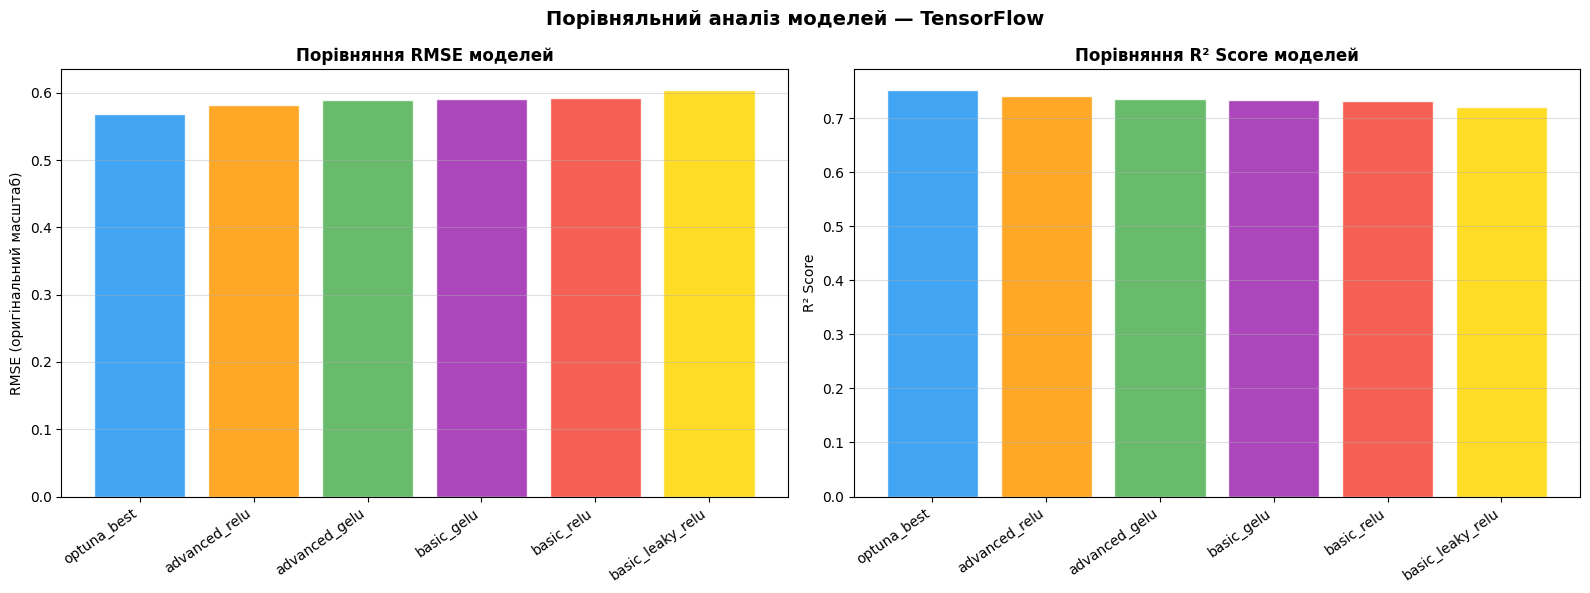

In [19]:
# --- Таблиця результатів ---
rows = []
for name, m in results.items():
    rows.append({
        'Модель': name,
        'MSE':  round(m['mse'], 4),
        'RMSE': round(m['rmse'], 4),
        'MAE':  round(m['mae'], 4),
        'R²':   round(m['r2'], 4),
        'Accuracy@10%': round(m['acc_10'], 2)
    })

df_results = pd.DataFrame(rows).sort_values('RMSE')
print('=== Результати всіх моделей (сортовано за RMSE) ===')
display(df_results.to_string(index=False))

# --- Барплот RMSE ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

bar_colors = ['#2196F3', '#FF9800', '#4CAF50', '#9C27B0', '#F44336', '#FFD700']
x = range(len(df_results))

axes[0].bar(x, df_results['RMSE'], color=bar_colors[:len(df_results)], alpha=0.85, edgecolor='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels(df_results['Модель'], rotation=35, ha='right', fontsize=10)
axes[0].set_ylabel('RMSE (оригінальний масштаб)')
axes[0].set_title('Порівняння RMSE моделей', fontweight='bold')
axes[0].grid(axis='y', alpha=0.4)

axes[1].bar(x, df_results['R²'], color=bar_colors[:len(df_results)], alpha=0.85, edgecolor='white')
axes[1].set_xticks(x)
axes[1].set_xticklabels(df_results['Модель'], rotation=35, ha='right', fontsize=10)
axes[1].set_ylabel('R² Score')
axes[1].set_title('Порівняння R² Score моделей', fontweight='bold')
axes[1].grid(axis='y', alpha=0.4)

plt.suptitle('Порівняльний аналіз моделей — TensorFlow', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('lab1_metrics_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

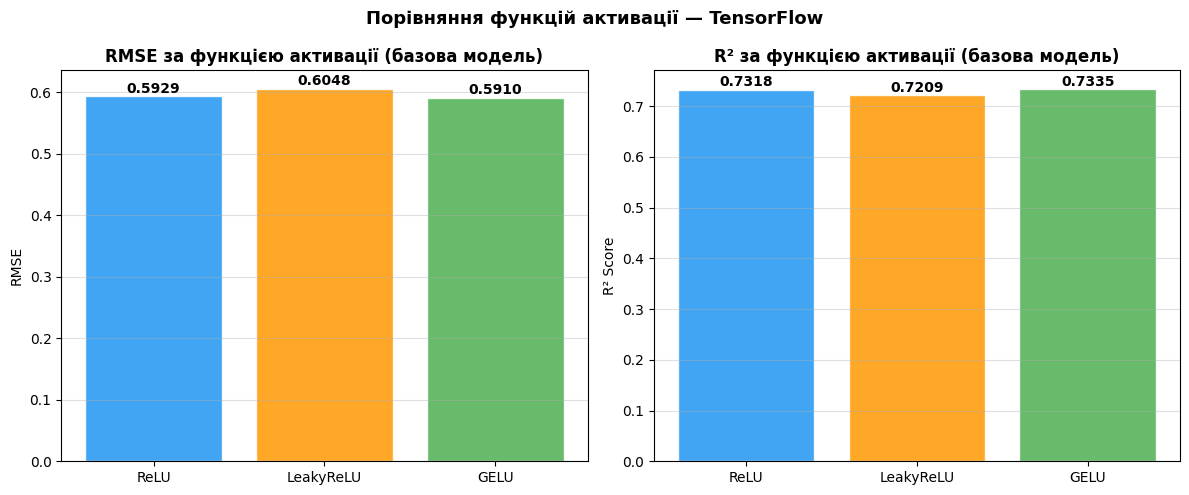

In [20]:
# --- Порівняння активацій на базовій моделі ---
act_names  = ['ReLU', 'LeakyReLU', 'GELU']
act_keys   = ['basic_relu', 'basic_leaky_relu', 'basic_gelu']
act_rmse   = [results[k]['rmse'] for k in act_keys if k in results]
act_r2     = [results[k]['r2']   for k in act_keys if k in results]
act_labels = [n for n, k in zip(act_names, act_keys) if k in results]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colors_act = ['#2196F3', '#FF9800', '#4CAF50']

axes[0].bar(act_labels, act_rmse, color=colors_act[:len(act_labels)], alpha=0.85, edgecolor='white')
for i, v in enumerate(act_rmse):
    axes[0].text(i, v + 0.001, f'{v:.4f}', ha='center', va='bottom', fontweight='bold')
axes[0].set_ylabel('RMSE')
axes[0].set_title('RMSE за функцією активації (базова модель)', fontweight='bold')
axes[0].grid(axis='y', alpha=0.4)

axes[1].bar(act_labels, act_r2, color=colors_act[:len(act_labels)], alpha=0.85, edgecolor='white')
for i, v in enumerate(act_r2):
    axes[1].text(i, v + 0.001, f'{v:.4f}', ha='center', va='bottom', fontweight='bold')
axes[1].set_ylabel('R² Score')
axes[1].set_title('R² за функцією активації (базова модель)', fontweight='bold')
axes[1].grid(axis='y', alpha=0.4)

plt.suptitle('Порівняння функцій активації — TensorFlow', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('lab1_activation_comparison.png', dpi=120, bbox_inches='tight')
plt.show()